In [2]:
import pandas as pd
import numpy as np
from fredapi import Fred
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import curve_fit

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

from scipy.optimize import minimize
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

# Initialize the client with your custom FRED API key
# Replace 'YOUR_API_KEY_HERE' with the actual key string from your account
API_KEY = '424034afb86bdcab88017369d65d00da'
fred = Fred(api_key=API_KEY)

# Label and FRED series id for each Treasury maturity
us_treasury = [
    ("1M", "DGS1MO"),   # 1-Month
    ("3M", "DGS3MO"),   # 3-Month
    ("6M", "DGS6MO"),   # 6-Month
    ("1Y", "DGS1"),     # 1-Year
    ("2Y", "DGS2"),     # 2-Year
    ("3Y", "DGS3"),     # 3-Year
    ("5Y", "DGS5"),     # 5-Year
    ("7Y", "DGS7"),     # 7-Year
    ("10Y", "DGS10"),   # 10-Year
    ("20Y", "DGS20"),   # 20-Year
    ("30Y", "DGS30"),   # 30-Year
]

# Fetch the time-series data for each maturity
data_dict = {}
for label, series_id in us_treasury:
    print(f"Fetching {label} Treasury Yield ({series_id})...")
    # Pull data from 2020 onward (adjust observation_start as needed)
    data_dict[label] = fred.get_series(series_id, observation_start='1900-01-01')

# Combine all series into a single pandas DataFrame
df_treasury = pd.DataFrame(data_dict)

# Clean up: Rename index to 'Date' and drop any days with missing data (like weekends/holidays)
df_treasury.index.name = 'Date'
df_treasury.dropna(inplace=True)

latest_rates = df_treasury.iloc[-1]
# Display the latest rates
print("\nLatest Treasury Rates (Par Yields)(%):")
print(latest_rates)

def par_to_continuous_zeros(par_pct, maturities):
    """Bootstrap semiannual Treasury par yields to continuously compounded zeros.

    par_pct are FRED constant-maturity par yields in percent. maturities are in
    years. The result is the continuous zero rate in percent, same order.
    Bills (up to 6 months) are treated as zeros. Longer par yields are
    bootstrapped on a semiannual coupon grid, with the par yield interpolated
    linearly between the quoted maturities.
    """
    par_pct = np.asarray(par_pct, dtype=float)
    maturities = np.asarray(maturities, dtype=float)
    order = np.argsort(maturities)
    tenors = maturities[order]
    coupons = par_pct[order] / 100.0

    n_periods = int(np.round(tenors[-1] * 2))
    grid = np.arange(1, n_periods + 1) / 2.0
    par_grid = np.interp(grid, tenors, coupons)

    discount = np.empty(n_periods)
    for n, coupon in enumerate(par_grid):
        if n == 0:
            discount[n] = 1.0 / (1.0 + coupon / 2.0)
        else:
            accrued = (coupon / 2.0) * discount[:n].sum()
            discount[n] = (1.0 - accrued) / (1.0 + coupon / 2.0)

    zeros = np.empty(len(tenors))
    for i, (tenor, coupon) in enumerate(zip(tenors, coupons)):
        if tenor <= 0.5:
            df = (1.0 + coupon / 2.0) ** (-2.0 * tenor)
        else:
            df = discount[int(np.round(tenor * 2)) - 1]
        zeros[i] = -np.log(df) / tenor * 100.0

    out = np.empty(len(tenors))
    out[order] = zeros
    return out



Fetching 1M Treasury Yield (DGS1MO)...
Fetching 3M Treasury Yield (DGS3MO)...
Fetching 6M Treasury Yield (DGS6MO)...
Fetching 1Y Treasury Yield (DGS1)...
Fetching 2Y Treasury Yield (DGS2)...
Fetching 3Y Treasury Yield (DGS3)...
Fetching 5Y Treasury Yield (DGS5)...
Fetching 7Y Treasury Yield (DGS7)...
Fetching 10Y Treasury Yield (DGS10)...
Fetching 20Y Treasury Yield (DGS20)...
Fetching 30Y Treasury Yield (DGS30)...

Latest Treasury Rates (Par Yields)(%):
1M     4.14
3M     4.23
6M     4.30
1Y     4.44
2Y     4.75
3Y     4.85
5Y     4.99
7Y     5.11
10Y    5.22
20Y    5.64
30Y    5.60
Name: 2026-10-08 00:00:00, dtype: float64


     par_rate_pct  maturity_years  yield_cc_pct  discount_factor
1M           4.14        0.083333      4.097733         0.996591
3M           4.23        0.250000      4.185889         0.989590
6M           4.30        0.500000      4.254427         0.978953
1Y           4.44        1.000000      4.392955         0.957021
2Y           4.75        2.000000      4.703504         0.910219
3Y           4.85        3.000000      4.803374         0.865800
5Y           4.99        5.000000      4.947503         0.780848
7Y           5.11        7.000000      5.076665         0.700916
10Y          5.22       10.000000      5.198966         0.594582
20Y          5.64       20.000000      5.779436         0.314778
30Y          5.60       30.000000      5.625544         0.184951


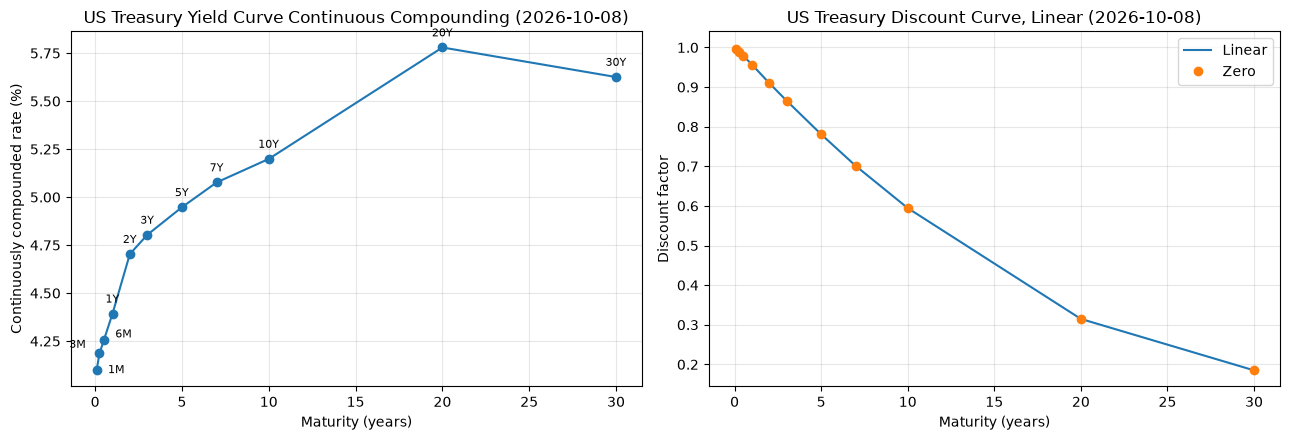

,par_rate_pct,maturity_years,yield_cc_pct,discount_factor
1M,4.14,0.083333,4.097733,0.996591
3M,4.23,0.250000,4.185889,0.989590
6M,4.30,0.500000,4.254427,0.978953
1Y,4.44,1.000000,4.392955,0.957021
2Y,4.75,2.000000,4.703504,0.910219
3Y,4.85,3.000000,4.803374,0.865800
5Y,4.99,5.000000,4.947503,0.780848
7Y,5.11,7.000000,5.076665,0.700916
10Y,5.22,10.000000,5.198966,0.594582
20Y,5.64,20.000000,5.779436,0.314778


In [3]:
latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

def zero_curve_table(par_rates):
    """One date of par yields (%) to maturities, continuous zeros (%) and discount factors."""
    table = par_rates.rename("par_rate_pct").to_frame()
    table["maturity_years"] = table.index.map(maturity_years)
    table = table.sort_values("maturity_years")
    # FRED quotes are semiannual par yields. Bootstrap them to continuous zeros.
    table["yield_cc_pct"] = par_to_continuous_zeros(
        table["par_rate_pct"].to_numpy(),
        table["maturity_years"].to_numpy(),
    )
    table["discount_factor"] = np.exp(
        -table["yield_cc_pct"] / 100 * table["maturity_years"]
    )
    return table

yield_curve = zero_curve_table(latest_rates)

tenors = yield_curve["maturity_years"].to_numpy()
yields = yield_curve["yield_cc_pct"].to_numpy()

# Each curve cell adds (maturities, zero rates in %) here for the arbitrage check.
fitted_curves = {}
linear_grid = np.linspace(tenors[0], tenors[-1], 400)
fitted_curves["Linear"] = (linear_grid, np.interp(linear_grid, tenors, yields))

print(yield_curve)
as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

def plot_discount_curve(ax, maturities, zero_pct, label):
    """Plot D(t) = exp(-r t) from continuous zero rates in percent, starting at 1 today."""
    maturities = np.asarray(maturities, dtype=float)
    discount = np.exp(-np.asarray(zero_pct, dtype=float) / 100 * maturities)
    ax.plot(
        np.concatenate([[0.0], maturities]),
        np.concatenate([[1.0], discount]),
        label=label,
    )
    ax.plot(
        tenors,
        yield_curve["discount_factor"],
        marker="o",
        linestyle="none",
        label="Zero",
    )
    ax.set_title(f"US Treasury Discount Curve, {label} ({as_of})")
    ax.set_xlabel("Maturity (years)")
    ax.set_ylabel("Discount factor")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig, (ax, ax_df) = plt.subplots(1, 2, figsize=(13, 4.5))
ax.plot(yield_curve["maturity_years"], yield_curve["yield_cc_pct"], marker="o")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve Continuous Compounding ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.grid(True, alpha=0.3)

plot_discount_curve(ax_df, tenors, yields, "Linear")
fig.tight_layout()
plt.show()

yield_curve


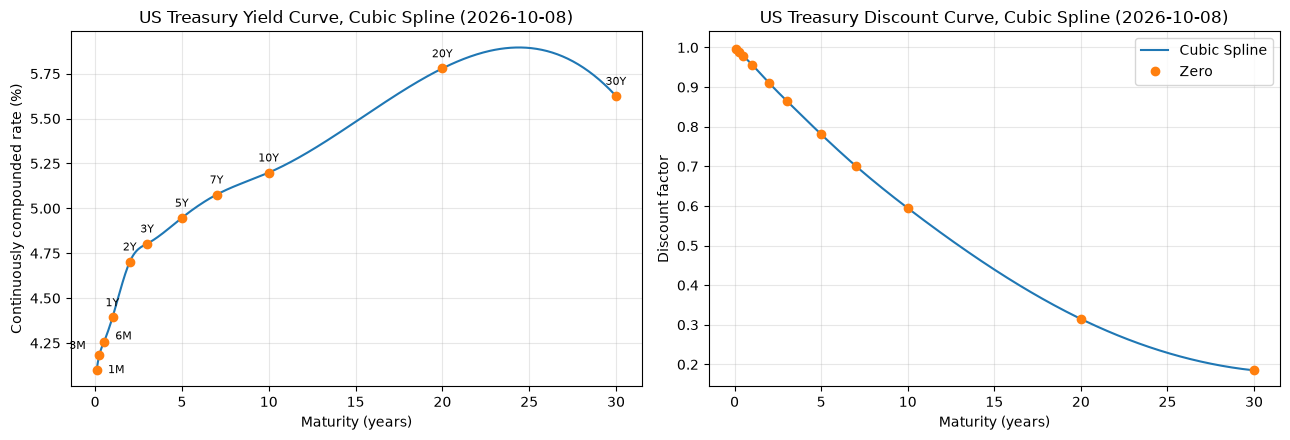

In [4]:
tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
continuous_spline = CubicSpline(tenors, yield_curve["yield_cc_pct"].to_numpy())
fitted_curves["Cubic spline"] = (tenor_grid, continuous_spline(tenor_grid))

fig, (ax, ax_df) = plt.subplots(1, 2, figsize=(13, 4.5))
ax.plot(tenor_grid, continuous_spline(tenor_grid))
ax.plot(tenors, yield_curve["yield_cc_pct"], marker="o", linestyle="none")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Cubic Spline ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.grid(True, alpha=0.3)
plot_discount_curve(ax_df, tenor_grid, continuous_spline(tenor_grid), "Cubic Spline")
fig.tight_layout()
plt.show()


The Nelson-Siegel curve is fitted to the continuously compounded yields:

$$
y(\tau)=\beta_0+\beta_1\frac{1-e^{-\tau/\lambda}}{\tau/\lambda}+\beta_2\left(\frac{1-e^{-\tau/\lambda}}{\tau/\lambda}-e^{-\tau/\lambda}\right)
$$

where $\tau$ is maturity in years. $\beta_0$ is the long-run level, $\beta_1$ is how far the short end sits from that level, $\beta_2$ is the hump, and $\lambda$ sets how fast the curve settles. Those four numbers are fitted to the eleven quoted yields.

Unlike the straight-line and cubic-spline charts, this curve does not pass through every quote. It is one smooth function, so a bend such as the dip from 20 years to 30 years can sit a few basis points off the dots.

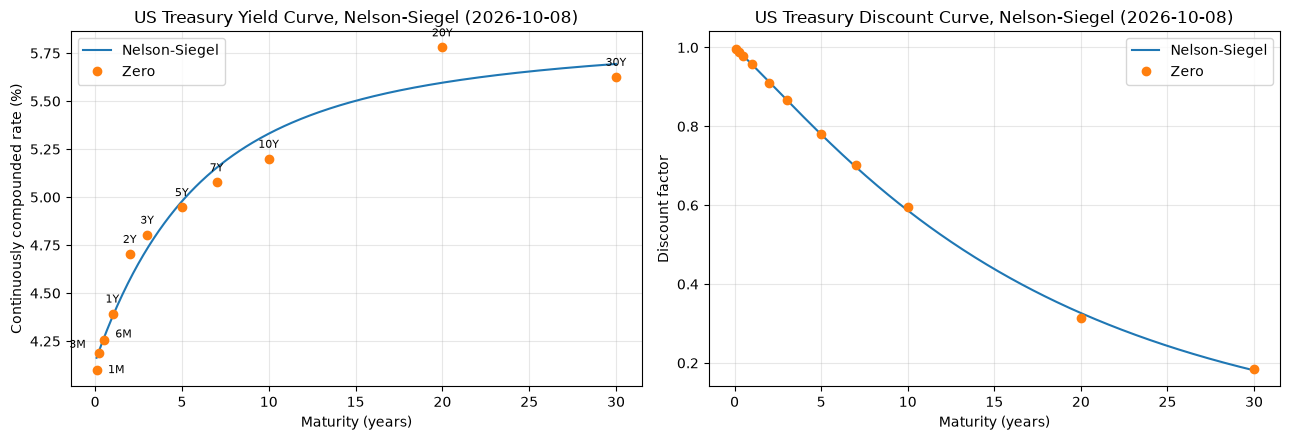

beta0 = 5.890  beta1 = -1.748  beta2 = 0.000  lambda = 3.375


In [5]:

def nelson_siegel(tau, beta0, beta1, beta2, lam):
    """Continuously compounded Nelson-Siegel yield at maturity tau (years)."""
    x = tau / lam
    exp_x = np.exp(-x)
    factor = np.where(np.abs(x) < 1e-8, 1.0, (1 - exp_x) / x)
    return beta0 + beta1 * factor + beta2 * (factor - exp_x)

def fit_nelson_siegel(tenors, yields):
    """Least-squares Nelson-Siegel parameters (beta0, beta1, beta2, lam)."""
    # beta0 ~ long rate, beta1 ~ short minus long, beta2 ~ hump, lam ~ decay in years
    p0 = [yields[-1], yields[0] - yields[-1], 0.0, 2.0]
    bounds = ([-5, -20, -20, 0.05], [20, 20, 20, 30])
    return curve_fit(nelson_siegel, tenors, yields, p0=p0, bounds=bounds)[0]

beta0, beta1, beta2, lam = fit_nelson_siegel(tenors, yields)

tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
fitted = nelson_siegel(tenor_grid, beta0, beta1, beta2, lam)
fitted_curves["Nelson-Siegel"] = (tenor_grid, fitted)

fig, (ax, ax_df) = plt.subplots(1, 2, figsize=(13, 4.5))
ax.plot(tenor_grid, fitted, label="Nelson-Siegel")
ax.plot(tenors, yields, marker="o", linestyle="none", label="Zero")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Nelson-Siegel ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plot_discount_curve(ax_df, tenor_grid, fitted, "Nelson-Siegel")
fig.tight_layout()
plt.show()

print(f"beta0 = {beta0:.3f}  beta1 = {beta1:.3f}  beta2 = {beta2:.3f}  lambda = {lam:.3f}")


Svensson adds a second hump to Nelson-Siegel:

$$
y(\tau)=\beta_0+\beta_1\frac{1-e^{-\tau/\lambda_1}}{\tau/\lambda_1}+\beta_2\left(\frac{1-e^{-\tau/\lambda_1}}{\tau/\lambda_1}-e^{-\tau/\lambda_1}\right)+\beta_3\left(\frac{1-e^{-\tau/\lambda_2}}{\tau/\lambda_2}-e^{-\tau/\lambda_2}\right)
$$

$\beta_3$ and $\lambda_2$ are that extra hump and its maturity. The fit tries a few starting points and keeps the one that is not stuck on a bound. Like Nelson-Siegel, the curve is one smooth function, so it does not pass through every quote. The second hump lets it follow a bend such as 20 years to 30 years more closely.

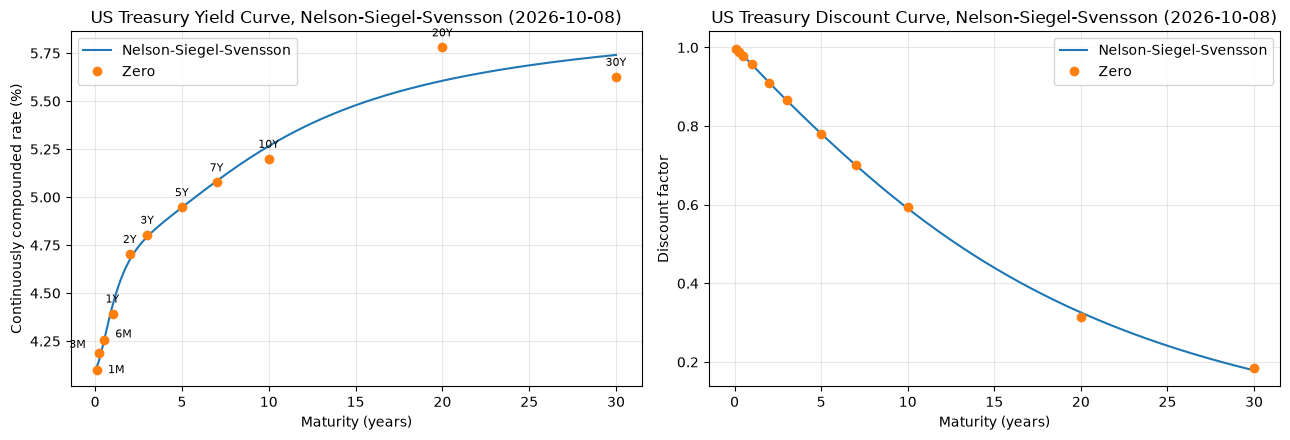

beta0 = 6.012  beta1 = -1.908  beta2 = -1.387  beta3 = -2.540  lambda1 = 0.469  lambda2 = 2.598


In [6]:
def nelson_siegel_svensson(tau, beta0, beta1, beta2, beta3, lam1, lam2):
    """Continuously compounded Nelson-Siegel-Svensson yield at maturity tau (years)."""
    def loadings(lam):
        x = tau / lam
        exp_x = np.exp(-x)
        level = np.where(np.abs(x) < 1e-8, 1.0, (1 - exp_x) / x)
        return level, level - exp_x

    slope, curve1 = loadings(lam1)
    _, curve2 = loadings(lam2)
    return beta0 + beta1 * slope + beta2 * curve1 + beta3 * curve2

def fit_nelson_siegel_svensson(tenors, yields):
    """Least-squares Svensson parameters (beta0, beta1, beta2, beta3, lam1, lam2)."""
    # Six parameters, so try a few starts and keep the best fit that is not stuck on a bound.
    bounds = ([3, -10, -10, -10, 0.1, 1.0], [10, 10, 10, 10, 5, 30])
    starts = [
        [yields[-1], yields[0] - yields[-1], 0.0, 0.0, 1.5, 8.0],
        [yields[-1], yields[0] - yields[-1], -1.0, -1.5, 0.5, 3.0],
        [yields[-1], yields[0] - yields[-1], -2.0, 2.0, 1.0, 10.0],
        [yields[-1], yields[0] - yields[-1], 2.0, -2.0, 2.0, 15.0],
    ]
    lower, upper = np.array(bounds[0]), np.array(bounds[1])
    best = None
    for start in starts:
        fitted_params = curve_fit(
            nelson_siegel_svensson, tenors, yields, p0=start, bounds=bounds, maxfev=20000
        )[0]
        residual = nelson_siegel_svensson(tenors, *fitted_params) - yields
        sse = np.sum(residual**2)
        on_bound = np.any(np.isclose(fitted_params, lower) | np.isclose(fitted_params, upper))
        if best is None or (on_bound, sse) < best[0]:
            best = ((on_bound, sse), fitted_params)
    return best[1]

beta0, beta1, beta2, beta3, lam1, lam2 = fit_nelson_siegel_svensson(tenors, yields)
tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
fitted = nelson_siegel_svensson(tenor_grid, beta0, beta1, beta2, beta3, lam1, lam2)
fitted_curves["Nelson-Siegel-Svensson"] = (tenor_grid, fitted)

fig, (ax, ax_df) = plt.subplots(1, 2, figsize=(13, 4.5))
ax.plot(tenor_grid, fitted, label="Nelson-Siegel-Svensson")
ax.plot(tenors, yields, marker="o", linestyle="none", label="Zero")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Nelson-Siegel-Svensson ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plot_discount_curve(ax_df, tenor_grid, fitted, "Nelson-Siegel-Svensson")
fig.tight_layout()
plt.show()

print(
    f"beta0 = {beta0:.3f}  beta1 = {beta1:.3f}  beta2 = {beta2:.3f}  beta3 = {beta3:.3f}  "
    f"lambda1 = {lam1:.3f}  lambda2 = {lam2:.3f}"
)


The curve is a Matérn function whose length scale and noise are learned from the eleven quotes. A small noise term means it is not forced through every point. The shaded band is the 95% range. It stays tight where maturities are close together, and it widens in the gaps from 10 to 20 years and from 20 to 30 years, where the data say less about the yield in between.

The Gaussian process does not take arbitrage into account.

A discount curve is free of static arbitrage only if the discount factor falls as maturity gets longer. With continuous compounding that discount factor is $e^{-y(\tau)\tau}$, and it falls only when the instantaneous forward stays non-negative:

$$
f(\tau)=y(\tau)+\tau\,y'(\tau)\ge 0
$$

The fit never checks that. It only learns a smooth curve and a noise level from the eleven quotes. The shaded band includes many paths whose forwards would go negative.

On the latest quotes, the mean curve happens to stay clear of that: its lowest instantaneous forward is about 4%, at the short end, and the forward is still about 4.6% at 30 years. That is a property of this dataset, not a constraint in the model.

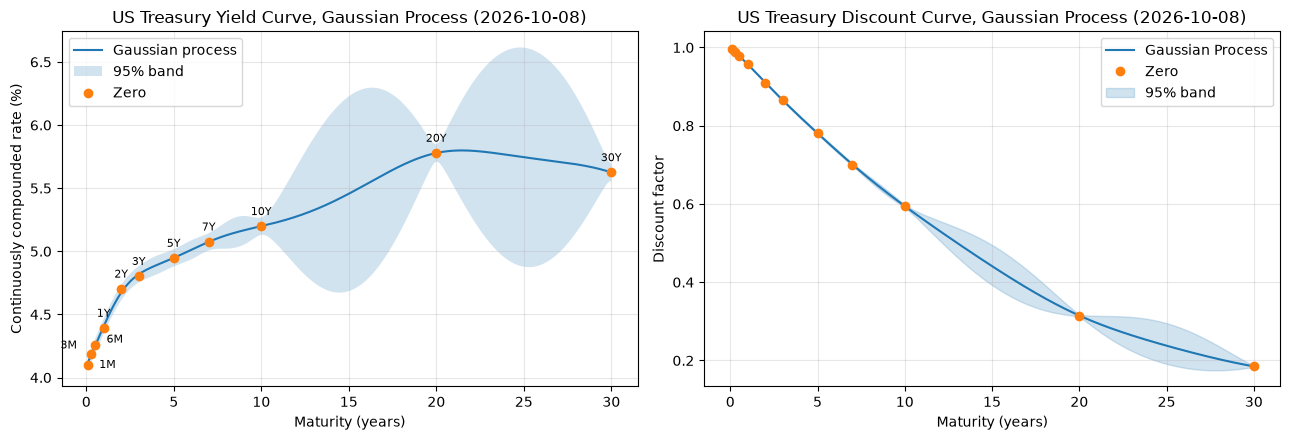

1.51**2 * Matern(length_scale=6.7, nu=2.5) + WhiteKernel(noise_level=0.00206)


In [7]:
def fit_gaussian_process(tenors, yields):
    """Gaussian process fitted to zero rates (%) by maturity (years)."""
    # Matérn kernel for a smooth curve, plus a little noise so the fit is not forced through every quote.
    kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(
        length_scale=5.0, length_scale_bounds=(0.2, 50.0), nu=2.5
    ) + WhiteKernel(noise_level=0.01, noise_level_bounds=(1e-5, 0.1))
    gp = GaussianProcessRegressor(
        kernel=kernel,
        n_restarts_optimizer=8,
        normalize_y=True,
        random_state=0,
    )
    return gp.fit(tenors.reshape(-1, 1), yields)

gp = fit_gaussian_process(tenors, yields)

tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
mean, std = gp.predict(tenor_grid.reshape(-1, 1), return_std=True)
fitted_curves["Gaussian process"] = (tenor_grid, mean)
fitted_curves["Gaussian process, upper band"] = (tenor_grid, mean + 2 * std)
fitted_curves["Gaussian process, lower band"] = (tenor_grid, mean - 2 * std)

fig, (ax, ax_df) = plt.subplots(1, 2, figsize=(13, 4.5))
ax.plot(tenor_grid, mean, label="Gaussian process")
ax.fill_between(
    tenor_grid,
    mean - 2 * std,
    mean + 2 * std,
    alpha=0.2,
    label="95% band",
)
ax.plot(tenors, yields, marker="o", linestyle="none", label="Zero")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Gaussian Process ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plot_discount_curve(ax_df, tenor_grid, mean, "Gaussian Process")
# A higher rate gives a lower discount factor, so the band edges swap.
ax_df.fill_between(
    tenor_grid,
    np.exp(-(mean + 2 * std) / 100 * tenor_grid),
    np.exp(-(mean - 2 * std) / 100 * tenor_grid),
    color="C0",
    alpha=0.2,
    label="95% band",
)
ax_df.legend()
fig.tight_layout()
plt.show()

print(gp.kernel_)


The no-arbitrage curve is built from a positive instantaneous forward. A latent function $g$ is a Gaussian process with a Matérn-$\tfrac{5}{2}$ kernel, and the forward is

$$
f(\tau)=\operatorname{softplus}(g(\tau))=\ln(1+e^{g(\tau)})>0.
$$

The continuously compounded zero rate is the average of that forward:

$$
y(\tau)=\frac{1}{\tau}\int_0^{\tau} f(s)\,ds.
$$

Because $f$ stays positive, the discount factor $e^{-y(\tau)\tau}$ falls as maturity increases. The latent curve is chosen by minimizing

$$
\sum_i \frac{\bigl(y(\tau_i)-y_i^{\mathrm{obs}}\bigr)^2}{\sigma^2}+\|w\|^2,
$$

where $y_i^{\mathrm{obs}}$ are the quoted yields, $\sigma=0.05$, and $w$ are the Gaussian-process weights.

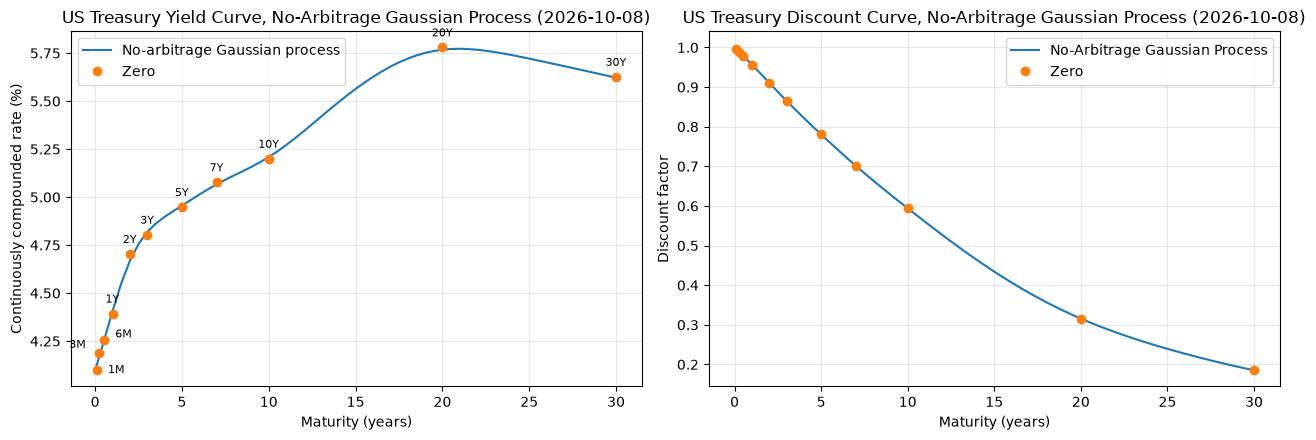

length scale = 3.0 years  minimum instantaneous forward = 4.10%


In [8]:
from scipy.optimize import minimize
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

def softplus(x):
    """Positive smooth map, so the instantaneous forward cannot go negative."""
    return np.log1p(np.exp(-np.abs(x))) + np.maximum(x, 0)

def fit_no_arbitrage_gp(tenors, yields, sigma=0.05):
    """Zero curve whose instantaneous forward is softplus of a Gaussian process.

    Returns the maturity grid, the zero rates and forwards on it (both in %),
    and the chosen length scale. sigma is the yield noise in percent.
    """
    # Latent curve g is a Gaussian process. The forward is softplus(g) > 0,
    # and the zero rate is the average of that forward up to each maturity.
    grid = np.unique(np.concatenate([np.linspace(0, tenors[-1], 61), tenors]))
    obs_idx = np.searchsorted(grid, tenors)

    def fit(length_scale):
        kernel = ConstantKernel(1.0) * Matern(length_scale=length_scale, nu=2.5)
        prior = kernel(grid.reshape(-1, 1))
        prior[np.diag_indices(len(grid))] += 1e-8
        weights_to_curve = np.linalg.cholesky(prior)

        def curve_from(weights):
            forward = softplus(np.mean(yields) + weights_to_curve @ weights)
            gaps = np.diff(grid)
            integral = np.concatenate(
                [[0.0], np.cumsum(0.5 * (forward[1:] + forward[:-1]) * gaps)]
            )
            zero = integral[1:] / grid[1:]
            return zero, forward

        def loss(weights):
            zero, _ = curve_from(weights)
            fitted = zero[obs_idx - 1]
            return np.sum((fitted - yields) ** 2) / sigma**2 + np.sum(weights**2)

        result = minimize(loss, np.zeros(len(grid)), method="L-BFGS-B")
        zero, forward = curve_from(result.x)
        return result.fun, zero, forward

    best = None
    for length_scale in (1.5, 2.0, 3.0, 5.0, 8.0):
        objective, zero, forward = fit(length_scale)
        if best is None or objective < best[0]:
            best = (objective, length_scale, zero, forward)

    _, length_scale, zero, forward = best
    return grid[1:], zero, forward, length_scale

no_arb_grid, zero, forward, length_scale = fit_no_arbitrage_gp(tenors, yields)
min_forward = forward.min()
fitted_curves["No-arbitrage Gaussian process"] = (no_arb_grid, zero)

fig, (ax, ax_df) = plt.subplots(1, 2, figsize=(13, 4.5))
ax.plot(no_arb_grid, zero, label="No-arbitrage Gaussian process")
ax.plot(tenors, yields, marker="o", linestyle="none", label="Zero")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, No-Arbitrage Gaussian Process ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plot_discount_curve(ax_df, no_arb_grid, zero, "No-Arbitrage Gaussian Process")
fig.tight_layout()
plt.show()

print(
    f"length scale = {length_scale:.1f} years  "
    f"minimum instantaneous forward = {min_forward:.2f}%"
)


A zero curve allows static arbitrage if its discount factor ever rises with maturity. That is the same as the instantaneous forward going negative:

$$
f(\tau) = -\frac{d}{d\tau}\ln D(\tau) = r(\tau) + \tau\, r'(\tau) \ge 0
$$

The check below takes each fitted curve, computes the forward between neighbouring maturities on its grid, and reports the lowest one. A curve passes if that lowest forward is positive.

In [ ]:
def lowest_forward(maturities, zero_pct):
    """Lowest forward rate (%) between grid points, and where it occurs."""
    maturities = np.concatenate([[0.0], np.asarray(maturities, dtype=float)])
    log_discount = np.concatenate(
        [[0.0], -np.asarray(zero_pct, dtype=float) / 100 * maturities[1:]]
    )
    forwards = -np.diff(log_discount) / np.diff(maturities) * 100
    i = np.argmin(forwards)
    return forwards[i], maturities[i + 1]

rows = []
for name, (maturities, zero_pct) in fitted_curves.items():
    forward, at = lowest_forward(maturities, zero_pct)
    rows.append(
        {
            "curve": name,
            "lowest_forward_pct": round(forward, 2),
            "at_years": round(at, 1),
            "arbitrage_free": forward > 0,
        }
    )

arbitrage_check = pd.DataFrame(rows).set_index("curve")
print(f"Arbitrage check ({as_of})")
arbitrage_check

Arbitrage check (2026-10-08)


,lowest_forward_pct,at_years,arbitrage_free
curve,,,
Linear,4.10,0.1,True
Cubic spline,2.51,30.0,True
Nelson-Siegel,4.16,0.1,True
Nelson-Siegel-Svensson,4.11,0.1,True
Gaussian process,4.12,0.1,True
"Gaussian process, upper band",-3.06,29.5,False
"Gaussian process, lower band",0.21,21.5,True
No-arbitrage Gaussian process,4.12,0.1,True


The cell below refits every curve on the last 50 dates in the dataset. For each date it bootstraps that day's par yields to continuous zeros, fits the linear, cubic-spline, Nelson-Siegel, Svensson, Gaussian-process and no-arbitrage Gaussian-process curves, and runs the same arbitrage check as above.

It shows one chart per curve type with a line for each date, a table of the lowest forward rate for each curve and date (any negative value allows arbitrage), and the fitted 10-year zero rate. The full results, with zero rates at every quoted maturity, are in `history`.

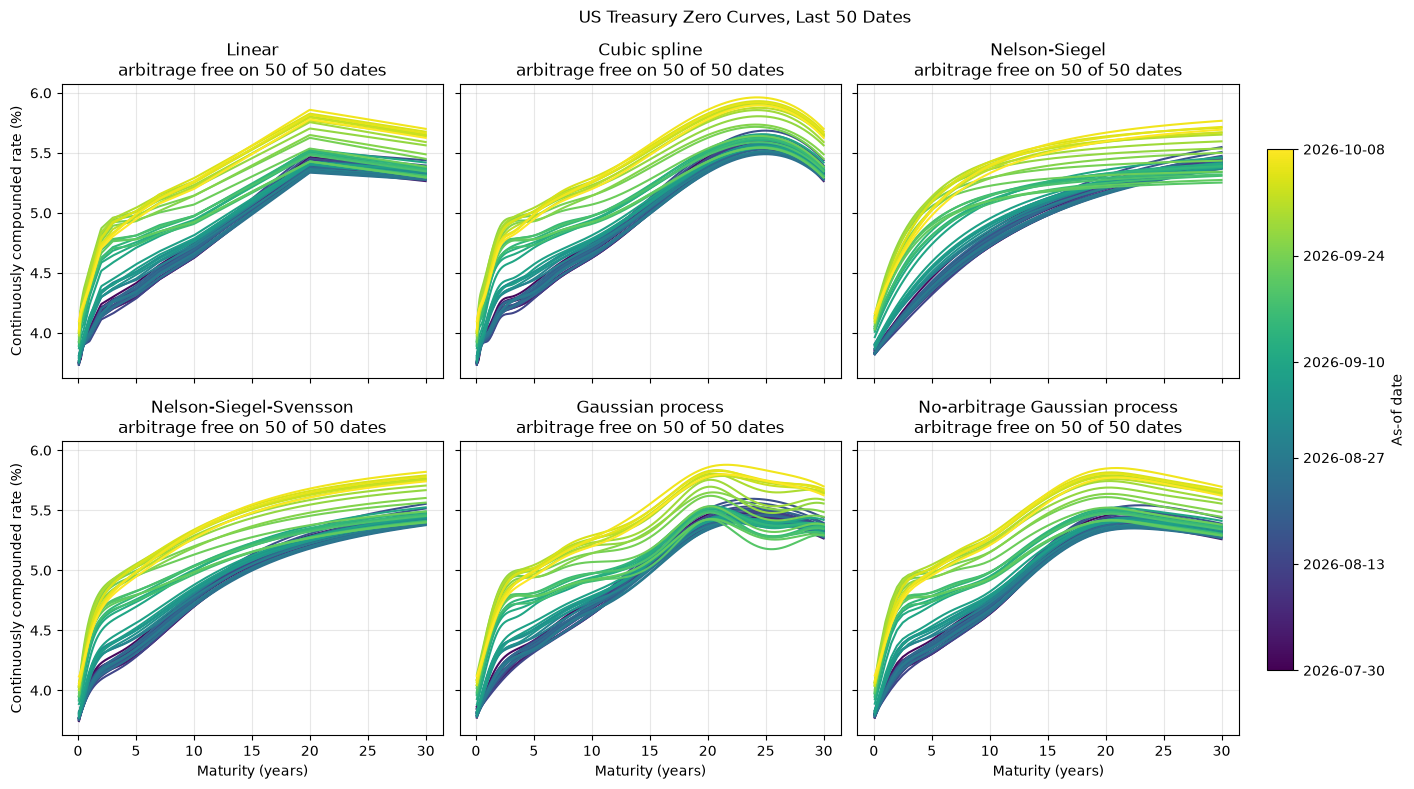

Arbitrage free by date and curve


curve,Linear,Cubic spline,Nelson-Siegel,Nelson-Siegel-Svensson,Gaussian process,No-arbitrage Gaussian process
date,,,,,,
2026-07-30,Yes,Yes,Yes,Yes,Yes,Yes
2026-07-31,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-03,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-04,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-05,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-06,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-07,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-10,Yes,Yes,Yes,Yes,Yes,Yes
2026-08-11,Yes,Yes,Yes,Yes,Yes,Yes


Lowest forward rate (%) by date and curve


curve,Linear,Cubic spline,Nelson-Siegel,Nelson-Siegel-Svensson,Gaussian process,No-arbitrage Gaussian process
date,,,,,,
2026-07-30,3.75,2.12,3.83,3.75,3.79,3.78
2026-07-31,3.74,2.28,3.84,3.74,3.77,3.77
2026-08-03,3.75,2.33,3.87,3.77,3.86,3.82
2026-08-04,3.74,2.15,3.86,3.76,3.86,3.80
2026-08-05,3.73,2.01,3.85,3.75,3.85,3.80
2026-08-06,3.76,2.40,3.87,3.78,3.82,3.81
2026-08-07,3.75,2.05,3.84,3.77,3.81,3.79
2026-08-10,3.75,2.34,3.85,3.77,3.84,3.80
2026-08-11,3.75,2.07,3.85,3.77,3.85,3.80


10-year zero rate (%) by date and curve


curve,Linear,Cubic spline,Nelson-Siegel,Nelson-Siegel-Svensson,Gaussian process,No-arbitrage Gaussian process
date,,,,,,
2026-07-30,4.675,4.675,4.775,4.744,4.677,4.686
2026-07-31,4.745,4.745,4.851,4.815,4.746,4.756
2026-08-03,4.695,4.694,4.789,4.762,4.694,4.705
2026-08-04,4.625,4.625,4.718,4.696,4.633,4.636
2026-08-05,4.626,4.625,4.717,4.699,4.631,4.636
2026-08-06,4.684,4.684,4.781,4.751,4.686,4.694
2026-08-07,4.646,4.646,4.740,4.719,4.648,4.657
2026-08-10,4.716,4.716,4.809,4.784,4.717,4.727
2026-08-11,4.697,4.697,4.791,4.773,4.701,4.708


In [10]:
def build_curves(t, y):
    """All six zero curves, as (maturities, zero rates in %), from zeros y (%) at maturities t."""
    t_grid = np.linspace(t[0], t[-1], 400)
    no_arb_t, no_arb_zero, _, _ = fit_no_arbitrage_gp(t, y)
    return {
        "Linear": (t_grid, np.interp(t_grid, t, y)),
        "Cubic spline": (t_grid, CubicSpline(t, y)(t_grid)),
        "Nelson-Siegel": (t_grid, nelson_siegel(t_grid, *fit_nelson_siegel(t, y))),
        "Nelson-Siegel-Svensson": (
            t_grid,
            nelson_siegel_svensson(t_grid, *fit_nelson_siegel_svensson(t, y)),
        ),
        "Gaussian process": (
            t_grid,
            fit_gaussian_process(t, y).predict(t_grid.reshape(-1, 1)),
        ),
        "No-arbitrage Gaussian process": (no_arb_t, no_arb_zero),
    }

history_dates = df_treasury.index[-50:]
history_curves = {}
history_rows = []

for date in history_dates:
    table = zero_curve_table(df_treasury.loc[date])
    curves = build_curves(
        table["maturity_years"].to_numpy(), table["yield_cc_pct"].to_numpy()
    )
    for name, (maturities, zero_pct) in curves.items():
        history_curves[(date, name)] = (maturities, zero_pct)
        forward, _ = lowest_forward(maturities, zero_pct)
        history_rows.append(
            {
                "date": date,
                "curve": name,
                **{
                    label: np.interp(maturity_years[label], maturities, zero_pct)
                    for label in table.index
                },
                "lowest_forward_pct": forward,
                "arbitrage_free": forward > 0,
            }
        )

history = pd.DataFrame(history_rows).set_index(["date", "curve"])

curve_names = list(curves)
colors = plt.cm.viridis(np.linspace(0, 1, len(history_dates)))
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, curve_names):
    passes = history.xs(name, level="curve")["arbitrage_free"]
    for color, date in zip(colors, history_dates):
        maturities, zero_pct = history_curves[(date, name)]
        ax.plot(
            maturities,
            zero_pct,
            color=color,
            # Dashed lines are dates where this curve allows arbitrage.
            linestyle="-" if passes[date] else "--",
            label=date.strftime("%Y-%m-%d"),
        )
    ax.set_title(f"{name}\narbitrage free on {passes.sum()} of {len(passes)} dates")
    ax.grid(True, alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("Maturity (years)")
for ax in axes[:, 0]:
    ax.set_ylabel("Continuously compounded rate (%)")
fig.suptitle(f"US Treasury Zero Curves, Last {len(history_dates)} Dates")
fig.tight_layout()
# Too many dates for a legend, so a color bar maps line color to date.
date_colors = plt.cm.ScalarMappable(
    cmap="viridis",
    norm=plt.Normalize(0, len(history_dates) - 1),
)
colorbar = fig.colorbar(date_colors, ax=axes, shrink=0.8, pad=0.02)
tick_positions = np.linspace(0, len(history_dates) - 1, 6).round().astype(int)
colorbar.set_ticks(tick_positions)
colorbar.set_ticklabels([history_dates[i].strftime("%Y-%m-%d") for i in tick_positions])
colorbar.set_label("As-of date")
plt.show()

print("Arbitrage free by date and curve")
display(
    history["arbitrage_free"]
    .unstack("curve")[curve_names]
    .replace({True: "Yes", False: "No"})
)
print("Lowest forward rate (%) by date and curve")
display(history["lowest_forward_pct"].unstack("curve")[curve_names].round(2))
print("10-year zero rate (%) by date and curve")
history["10Y"].unstack("curve")[curve_names].round(3)

## Out-of-sample test: leave out 3M and 5Y

A curve that passes through every quote can look perfect in-sample, so here we test how well each method **predicts rates it has not seen**.

For each of the last 50 dates:

1. Drop the 3M and 5Y par yields from the FRED quotes.
2. Bootstrap the remaining 9 par yields to continuous zero rates and build all six curves.
3. Read the estimated zero rates at 3 months and 5 years off each curve.
4. Convert those back to par yields, so they can be compared with the real FRED quotes.

From a continuous zero curve $r(t)$ the discount factor is $D(t) = e^{-r(t)\,t}$. The 3M bill is quoted as a bond-equivalent yield, so

$$
y_{3M} = 2\left(D(0.25)^{-1/(2 \cdot 0.25)} - 1\right).
$$

The 5Y note pays semiannual coupons, and its par yield is the coupon that prices the bond at 100:

$$
y_{5Y} = \frac{2\,\bigl(1 - D(5)\bigr)}{\sum_{i=1}^{10} D(i/2)}.
$$

The error is the estimate minus the real quote, in basis points (1bp = 0.01%). We also compare the estimated zero rate with the zero bootstrapped from the full set of 11 quotes.

/home/kris/school/project/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/kris/school/project/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/kris/school/project/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/kris/school/project/.venv/lib/p

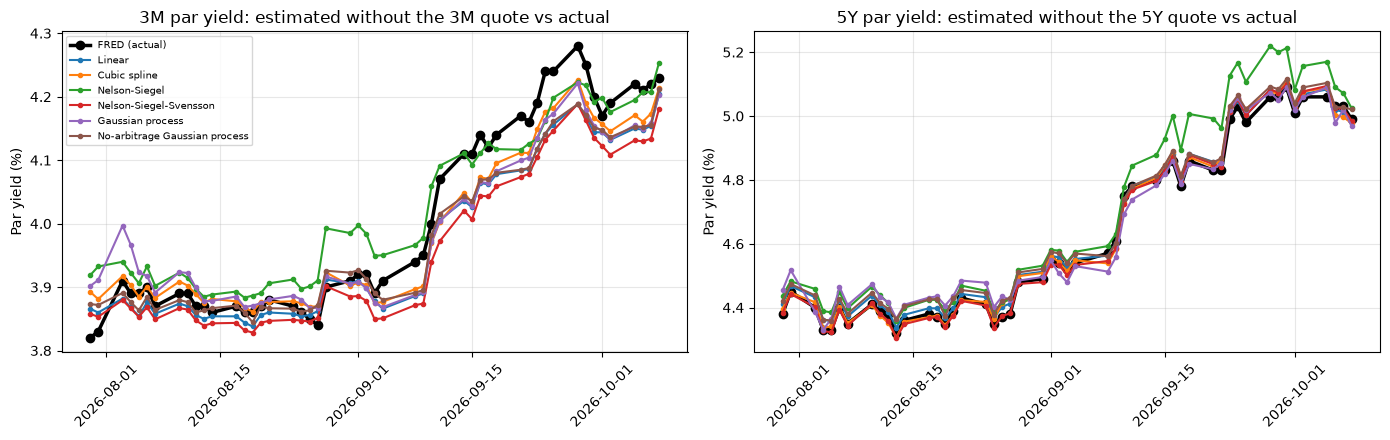

Par yield error by date (bp, estimate minus FRED)


3M                                                    \
           Linear Cubic spline Nelson-Siegel Nelson-Siegel-Svensson   
date                                                                  
2026-07-30    4.6          7.3           9.9                    3.8   
2026-07-31    3.0          5.1          10.2                    2.3   
2026-08-03   -2.8          0.7           3.0                   -3.0   
2026-08-04   -2.2          1.3           3.3                   -2.4   
2026-08-05   -3.6         -0.5           1.6                   -3.7   
2026-08-06   -2.4          0.1           3.3                   -3.2   
2026-08-07   -1.2          1.3           3.2                   -2.1   
2026-08-10   -1.6          1.9           3.3                   -2.3   
2026-08-11   -2.0          1.2           2.4                   -2.5   
2026-08-12   -1.4          1.9           2.8                   -2.2   
2026-08-13   -2.0          0.5           1.5                   -3.1   
2026-08-14   -0.6          2.1           2.8                   -1.7   
2026-08-17   -1.6          0.8           2.3                   -2.6   
2026-08-18   -1.6          0.8           2.3                   -2.8   
2026-08-19   -2.2          0.1           2.7                   -3.2   
2026-08-20   -1.4          0.6           2.0                   -2.6   
2026-08-21   -2.0         -0.4           2.6                   -3.3   
2026-08-24   -1.2          0.8           4.2                   -2.2   
2026-08-25   -0.6          1.5           3.7                   -1.3   
2026-08-26    0.6          1.9           5.1                   -0.4   
2026-08-27    2.2          2.9           7.0                    1.1   
2026-08-28    1.2          2.3           9.3                    0.1   
2026-08-31   -0.4         -0.8           7.5                   -2.5   
2026-09-01   -1.0         -1.3           7.7                   -3.4   
2026-09-02   -2.2         -1.7           6.4                   -4.2   
2026-09-03   -1.2         -1.6           5.9                   -4.0   
2026-09-04   -4.4         -3.3           4.0                   -5.9   
2026-09-08   -5.4         -4.3           2.6                   -6.8   
2026-09-09   -6.0         -4.9           2.8                   -7.6   
2026-09-10   -2.6         -3.1           5.9                   -6.0   
2026-09-11   -6.4         -6.8           2.1                   -9.8   
2026-09-14   -7.4         -6.1           0.1                   -8.9   
2026-09-15   -8.4         -7.7          -1.7                  -10.3   
2026-09-16   -7.6         -6.7          -2.9                   -9.6   
2026-09-17   -5.8         -4.9           0.6                   -7.7   
2026-09-18   -6.2         -4.5          -2.3                   -8.1   
2026-09-21   -8.6         -5.8          -5.4                   -9.7   
2026-09-22   -7.4         -4.9          -3.4                   -8.1   
2026-09-23   -7.2         -4.1          -5.6                   -8.5   
2026-09-24   -9.8         -6.4          -7.8                  -10.8   
2026-09-25   -8.4         -5.8          -4.2                   -9.3   
2026-09-28   -9.2         -5.3          -5.7                   -9.1   
2026-09-29   -8.2         -6.0          -3.2                   -8.7   
2026-09-30   -5.6         -3.3          -0.8                   -6.5   
2026-10-01   -2.6         -1.3           2.8                   -4.8   
2026-10-02   -5.8         -4.5          -1.4                   -8.1   
2026-10-05   -7.0         -4.9          -2.5                   -8.9   
2026-10-06   -6.2         -4.9          -0.3                   -8.0   
2026-10-07   -6.6         -4.7          -1.3                   -8.6   
2026-10-08   -2.6         -1.7           2.4                   -4.9   

                                                              5Y               \
           Gaussian process No-arbitrage Gaussian process Linear Cubic spline   
date                                                                            
2026-07-

Out-of-sample error summary over 50 dates (bp)


mean_error_bp  mean_abs_error_bp  rmse_bp  \
3M Linear                                  -3.6                4.0      4.9   
   Cubic spline                            -1.7                3.1      3.8   
   Nelson-Siegel                            1.8                3.8      4.5   
   Nelson-Siegel-Svensson                  -4.9                5.2      6.1   
   Gaussian process                        -1.6                4.2      4.9   
   No-arbitrage Gaussian process           -2.8                3.6      4.6   
5Y Linear                                   1.5                1.8      2.0   
   Cubic spline                             0.6                1.7      2.1   
   Nelson-Siegel                            6.8                6.8      8.0   
   Nelson-Siegel-Svensson                  -0.1                1.2      1.4   
   Gaussian process                         1.6                3.3      4.0   
   No-arbitrage Gaussian process            2.8                2.9      3.2   

                                  zero_rmse_bp  
3M Linear                                  4.8  
   Cubic spline                            3.8  
   Nelson-Siegel                           4.4  
   Nelson-Siegel-Svensson                  5.9  
   Gaussian process                        4.8  
   No-arbitrage Gaussian process           4.5  
5Y Linear                                  2.1  
   Cubic spline                            2.2  
   Nelson-Siegel                           8.8  
   Nelson-Siegel-Svensson                  1.5  
   Gaussian process                        4.3  
   No-arbitrage Gaussian process           3.3

In [ ]:
held_out = ["3M", "5Y"]

def par_from_zero(maturities, zero_pct, tenor):
    """Treasury par yield (%) at tenor implied by a continuous zero curve (%)."""
    if tenor <= 0.5:
        discount = np.exp(-np.interp(tenor, maturities, zero_pct) / 100 * tenor)
        return 2 * (discount ** (-1 / (2 * tenor)) - 1) * 100
    coupon_times = np.arange(1, int(round(tenor * 2)) + 1) / 2
    discount = np.exp(-np.interp(coupon_times, maturities, zero_pct) / 100 * coupon_times)
    return 2 * (1 - discount[-1]) / discount.sum() * 100

holdout_rows = []
for date in history_dates:
    actual_zero = zero_curve_table(df_treasury.loc[date])["yield_cc_pct"]
    table = zero_curve_table(df_treasury.loc[date].drop(held_out))
    curves = build_curves(
        table["maturity_years"].to_numpy(), table["yield_cc_pct"].to_numpy()
    )
    for name, (maturities, zero_pct) in curves.items():
        for label in held_out:
            tenor = maturity_years[label]
            est_par = par_from_zero(maturities, zero_pct, tenor)
            est_zero = np.interp(tenor, maturities, zero_pct)
            holdout_rows.append(
                {
                    "date": date,
                    "curve": name,
                    "tenor": label,
                    "actual_par_pct": df_treasury.loc[date, label],
                    "estimated_par_pct": est_par,
                    "par_error_bp": (est_par - df_treasury.loc[date, label]) * 100,
                    "zero_error_bp": (est_zero - actual_zero[label]) * 100,
                }
            )

holdout = pd.DataFrame(holdout_rows)

fig, axes = plt.subplots(1, len(held_out), figsize=(14, 4.5))
for ax, label in zip(axes, held_out):
    rows = holdout[holdout["tenor"] == label]
    actual = rows.drop_duplicates("date").set_index("date")["actual_par_pct"]
    ax.plot(actual.index, actual, color="black", marker="o", linewidth=2.5, label="FRED (actual)")
    for name in curve_names:
        est = rows[rows["curve"] == name].set_index("date")["estimated_par_pct"]
        ax.plot(est.index, est, marker=".", label=name)
    ax.set_title(f"{label} par yield: estimated without the {label} quote vs actual")
    ax.set_ylabel("Par yield (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

summary = holdout.groupby(["tenor", "curve"]).agg(
    mean_error_bp=("par_error_bp", "mean"),
    mean_abs_error_bp=("par_error_bp", lambda e: e.abs().mean()),
    rmse_bp=("par_error_bp", lambda e: np.sqrt((e**2).mean())),
    zero_rmse_bp=("zero_error_bp", lambda e: np.sqrt((e**2).mean())),
)
print("Par yield error by date (bp, estimate minus FRED)")
display(
    holdout.pivot_table(index="date", columns=["tenor", "curve"], values="par_error_bp")
    .reindex(columns=pd.MultiIndex.from_product([held_out, curve_names]))
    .round(1)
)
print(f"Out-of-sample error summary over {len(history_dates)} dates (bp)")
summary.reindex(pd.MultiIndex.from_product([held_out, curve_names])).round(1)

## A `YieldCurve` class

The class below wraps everything above into one object. You give it one date of FRED par yields (a pandas Series indexed by `"1M"`, `"3M"`, ..., `"30Y"`) and a fitting method. It then:

1. Bootstraps the par yields to continuously compounded zero rates.
2. Fits a zero curve $r(t)$ through them with the chosen method. The default is `"linear"`.
3. Derives the other curves from $r(t)$:

$$
D(t) = e^{-r(t)\,t}, \qquad f(t) = \frac{d}{dt}\bigl(r(t)\,t\bigr) = r(t) + t\,r'(t).
$$

The methods are `"linear"`, `"cubic_spline"`, `"nelson_siegel"`, `"nss"`, `"gp"` and `"no_arb_gp"`. For `"no_arb_gp"` the forward curve is the model's own softplus forward, so it is positive by construction. For the others it is a numerical derivative of $r(t)\,t$.

The main methods are `zero(t)`, `forward(t)`, `discount(t)` and `par(t)`, which all accept a maturity in years or an array of them, plus `curves()`, `is_arbitrage_free()` and `plot()`.

YieldCurve(method='linear', as_of=2026-10-08, quotes=['1M', '3M', '6M', '1Y', '2Y', '3Y', '5Y', '7Y', '10Y', '20Y', '30Y'])


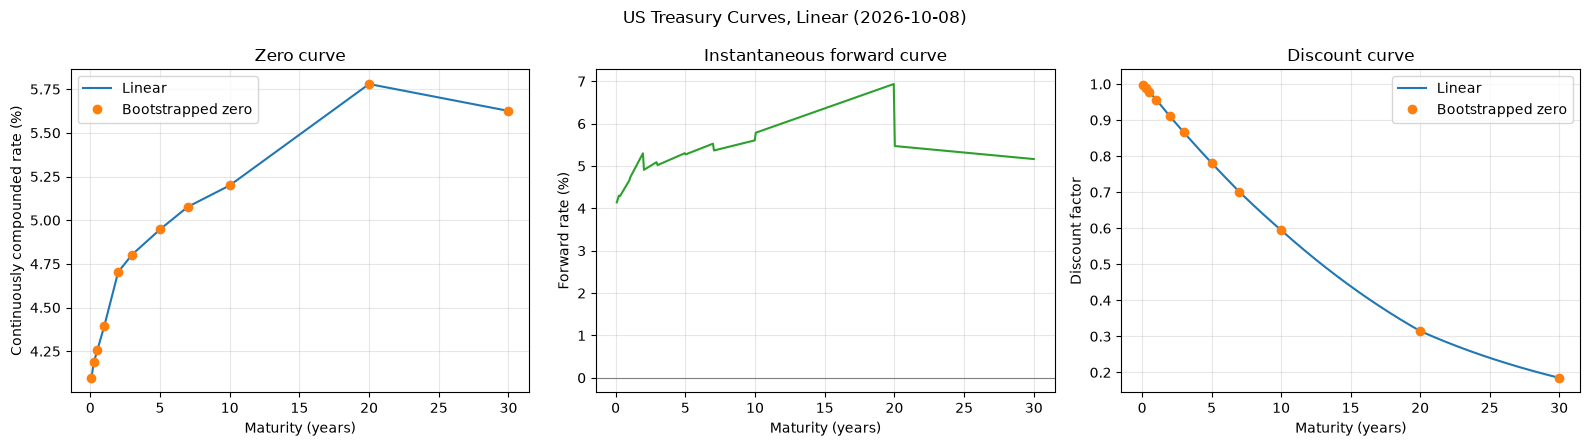

,10Y zero (%),10Y forward (%),10Y discount factor,5Y par from curve (%),arbitrage free
Linear,5.198966,5.693037,0.594582,4.990058,True
Cubic spline,5.198966,5.618542,0.594582,4.990127,True
Nelson-Siegel,5.330663,5.799928,0.586803,5.013322,True
Nelson-Siegel-Svensson,5.265747,5.803806,0.590625,4.988888,True
Gaussian process,5.199249,5.525317,0.594565,4.991546,True
No-arbitrage Gaussian process,5.208934,5.772786,0.59399,4.998871,True


In [12]:
class YieldCurve:
    """Continuously compounded zero, forward and discount curves built from one date of par yields."""

    METHODS = {
        "linear": "Linear",
        "cubic_spline": "Cubic spline",
        "nelson_siegel": "Nelson-Siegel",
        "nss": "Nelson-Siegel-Svensson",
        "gp": "Gaussian process",
        "no_arb_gp": "No-arbitrage Gaussian process",
    }

    def __init__(self, par_rates, method="linear"):
        if method not in self.METHODS:
            raise ValueError(f"method must be one of {list(self.METHODS)}, got {method!r}")
        par_rates = pd.Series(par_rates, dtype=float).dropna()
        self.method = method
        self.name = self.METHODS[method]
        self.as_of = par_rates.name
        self.quotes = zero_curve_table(par_rates)
        self.maturities = self.quotes["maturity_years"].to_numpy()
        self.zeros = self.quotes["yield_cc_pct"].to_numpy()
        self._model_forward = None
        self._zero_fn = self._fit(self.maturities, self.zeros)

    def _fit(self, t, y):
        """Return a function from maturities (array, years) to zero rates (%)."""
        if self.method == "linear":
            return lambda x: np.interp(x, t, y)
        if self.method == "cubic_spline":
            return CubicSpline(t, y)
        if self.method == "nelson_siegel":
            params = fit_nelson_siegel(t, y)
            return lambda x: nelson_siegel(x, *params)
        if self.method == "nss":
            params = fit_nelson_siegel_svensson(t, y)
            return lambda x: nelson_siegel_svensson(x, *params)
        if self.method == "gp":
            gp = fit_gaussian_process(t, y)
            return lambda x: gp.predict(x.reshape(-1, 1))
        grid, zero, forward, _ = fit_no_arbitrage_gp(t, y)
        forward_grid = np.concatenate([[0.0], grid])
        self._model_forward = lambda x: np.interp(x, forward_grid, forward)
        return lambda x: np.interp(x, grid, zero)

    @staticmethod
    def _evaluate(fn, t):
        """Apply fn to a scalar or array of maturities, returning the same shape."""
        t_arr = np.atleast_1d(np.asarray(t, dtype=float))
        out = np.asarray(fn(t_arr), dtype=float).reshape(t_arr.shape)
        return out.item() if np.ndim(t) == 0 else out

    def zero(self, t):
        """Continuously compounded zero rate (%) at maturity t (years)."""
        return self._evaluate(self._zero_fn, t)

    def discount(self, t):
        """Discount factor D(t) = exp(-r(t) t)."""
        return np.exp(-np.asarray(self.zero(t)) / 100 * np.asarray(t, dtype=float))

    def forward(self, t):
        """Instantaneous forward rate (%) at maturity t (years)."""
        if self._model_forward is not None:
            return self._evaluate(self._model_forward, t)

        # One-sided at the shortest and longest quote, where some curves go flat.
        def numerical(x, h=1e-4):
            lo = np.clip(x - h, self.maturities[0], None)
            hi = np.clip(x + h, None, self.maturities[-1])
            return (self._zero_fn(hi) * hi - self._zero_fn(lo) * lo) / (hi - lo)

        return self._evaluate(numerical, t)

    def par(self, t):
        """Treasury par yield (%) implied by the curve: bill yield up to 6 months, semiannual coupon after."""
        def par_one(tenor):
            if tenor <= 0.5:
                return 2 * (self.discount(tenor) ** (-1 / (2 * tenor)) - 1) * 100
            coupon_times = np.arange(1, int(round(tenor * 2)) + 1) / 2
            discount = self.discount(coupon_times)
            return 2 * (1 - discount[-1]) / discount.sum() * 100

        return self._evaluate(lambda x: np.array([par_one(tenor) for tenor in x]), t)

    def curves(self, n_points=400):
        """Zero, forward and discount curves on an even grid between the shortest and longest quote."""
        grid = np.linspace(self.maturities[0], self.maturities[-1], n_points)
        return pd.DataFrame(
            {
                "zero_cc_pct": self.zero(grid),
                "forward_pct": self.forward(grid),
                "discount_factor": self.discount(grid),
            },
            index=pd.Index(grid, name="maturity_years"),
        )

    def is_arbitrage_free(self):
        """True if the forward rate stays positive, so the discount curve keeps falling."""
        return bool(self.curves()["forward_pct"].min() > 0)

    def plot(self):
        """Zero curve with the bootstrapped quotes, forward curve and discount curve side by side."""
        curves = self.curves()
        fig, (ax_zero, ax_fwd, ax_df) = plt.subplots(1, 3, figsize=(16, 4.5))
        ax_zero.plot(curves.index, curves["zero_cc_pct"], label=self.name)
        ax_zero.plot(self.maturities, self.zeros, marker="o", linestyle="none", label="Bootstrapped zero")
        ax_zero.set_title("Zero curve")
        ax_zero.set_ylabel("Continuously compounded rate (%)")
        ax_fwd.plot(curves.index, curves["forward_pct"], color="C2")
        ax_fwd.axhline(0, color="grey", linewidth=0.8)
        ax_fwd.set_title("Instantaneous forward curve")
        ax_fwd.set_ylabel("Forward rate (%)")
        ax_df.plot(
            np.concatenate([[0.0], curves.index]),
            np.concatenate([[1.0], curves["discount_factor"]]),
            label=self.name,
        )
        ax_df.plot(self.maturities, self.quotes["discount_factor"], marker="o", linestyle="none", label="Bootstrapped zero")
        ax_df.set_title("Discount curve")
        ax_df.set_ylabel("Discount factor")
        for ax in (ax_zero, ax_fwd, ax_df):
            ax.set_xlabel("Maturity (years)")
            ax.grid(True, alpha=0.3)
        ax_zero.legend()
        ax_df.legend()
        as_of = self.as_of.strftime("%Y-%m-%d") if hasattr(self.as_of, "strftime") else self.as_of
        fig.suptitle(f"US Treasury Curves, {self.name} ({as_of})")
        fig.tight_layout()
        plt.show()

    def __repr__(self):
        as_of = self.as_of.strftime("%Y-%m-%d") if hasattr(self.as_of, "strftime") else self.as_of
        return f"YieldCurve(method={self.method!r}, as_of={as_of}, quotes={list(self.quotes.index)})"


curve = YieldCurve(latest_rates)
print(curve)
curve.plot()

summary = pd.DataFrame(
    {
        YieldCurve.METHODS[method]: {
            "10Y zero (%)": c.zero(10),
            "10Y forward (%)": c.forward(10),
            "10Y discount factor": c.discount(10),
            "5Y par from curve (%)": c.par(5),
            "arbitrage free": c.is_arbitrage_free(),
        }
        for method in YieldCurve.METHODS
        for c in [YieldCurve(latest_rates, method)]
    }
).T
summary